In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
df = pd.read_csv("../data/ai4i2020.csv")

df = df.rename(columns={
    "UDI": "udi",
    "Product ID": "product_id",
    "Type": "type",
    "Air temperature [K]": "air_temperature",
    "Process temperature [K]": "process_temperature",
    "Rotational speed [rpm]": "rotational_speed",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Machine failure": "machine_failure"
})

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Dataset shape: (10000, 14)


,udi,product_id,type,air_temperature,process_temperature,rotational_speed,torque,tool_wear,machine_failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df["temperature_difference"] = (
    df["process_temperature"] - df["air_temperature"]
)

df["mechanical_power"] = (
    df["torque"] * df["rotational_speed"] * (2 * np.pi / 60)
)

df["wear_torque_interaction"] = (
    df["tool_wear"] * df["torque"]
)

features = [
    "type",
    "air_temperature",
    "process_temperature",
    "rotational_speed",
    "torque",
    "tool_wear",
    "temperature_difference",
    "mechanical_power",
    "wear_torque_interaction"
]

target = "machine_failure"

X = df[features]
y = df[target]

print("Feature count:", len(features))
print("Target distribution:")
print(y.value_counts())

Feature count: 9
Target distribution:
machine_failure
0    9661
1     339
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8000
Testing samples: 2000


In [5]:
categorical_features = ["type"]

numerical_features = [
    col for col in features
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Original feature count:", X_train_processed.shape[1])
print("Training matrix:", X_train_processed.shape)
print("Testing matrix:", X_test_processed.shape)

Original feature count: 11
Training matrix: (8000, 11)
Testing matrix: (2000, 11)


In [6]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_processed)
X_test_pca = pca.transform(X_test_processed)

print("Features before PCA:", X_train_processed.shape[1])
print("Components after PCA:", pca.n_components_)

print(
    "Variance retained:",
    round(np.sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

Features before PCA: 11
Components after PCA: 5
Variance retained: 95.49 %


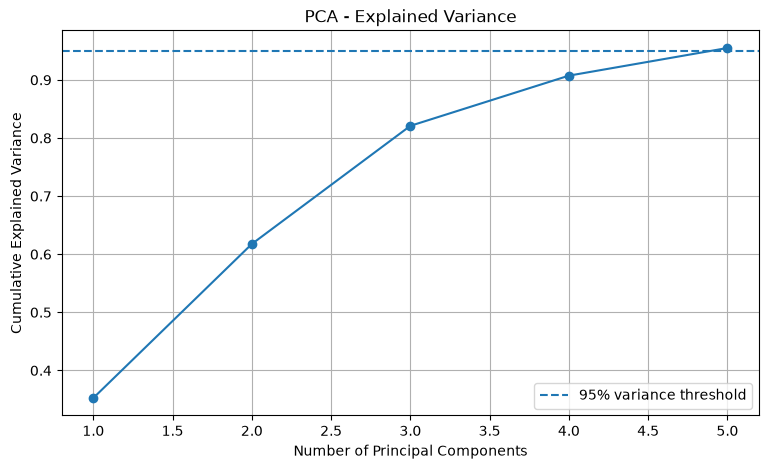

In [7]:
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% variance threshold"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Explained Variance")
plt.legend()
plt.grid()
plt.show()

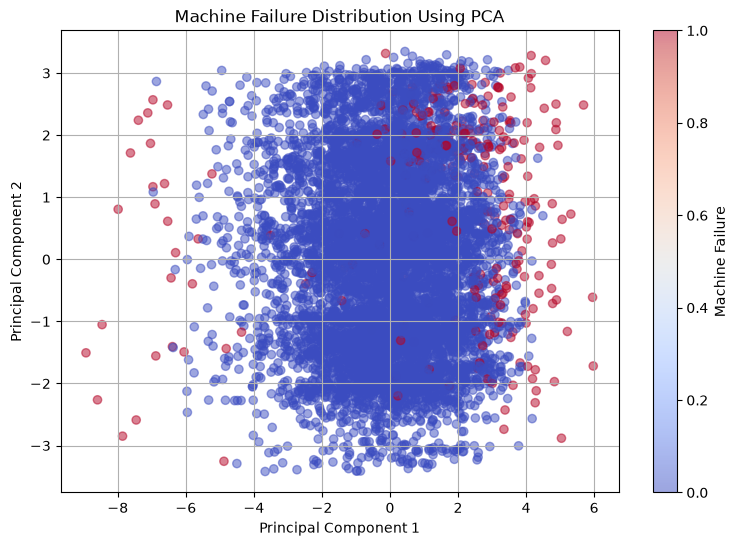

In [8]:
pca_2d = PCA(n_components=2)

X_train_2d = pca_2d.fit_transform(X_train_processed)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_train_2d[:, 0],
    X_train_2d[:, 1],
    c=y_train,
    cmap="coolwarm",
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Machine Failure Distribution Using PCA")
plt.colorbar(label="Machine Failure")
plt.grid()
plt.show()

In [9]:
model_original = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

model_original.fit(X_train_processed, y_train)

pred_original = model_original.predict(X_test_processed)

prob_original = model_original.predict_proba(
    X_test_processed
)[:, 1]

print("Baseline Logistic Regression trained.")

Baseline Logistic Regression trained.


In [10]:
model_pca = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

model_pca.fit(X_train_pca, y_train)

pred_pca = model_pca.predict(X_test_pca)

prob_pca = model_pca.predict_proba(
    X_test_pca
)[:, 1]

print("PCA Logistic Regression trained.")

PCA Logistic Regression trained.


In [11]:
from sklearn.metrics import average_precision_score

def evaluate_model(y_true, predictions, probabilities):
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(
            y_true, probabilities
        )
    }


original_metrics = evaluate_model(
    y_test, pred_original, prob_original
)

pca_metrics = evaluate_model(
    y_test, pred_pca, prob_pca
)

comparison = pd.DataFrame(
    [original_metrics, pca_metrics],
    index=["Without PCA", "With PCA"]
)

display(comparison.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Without PCA,0.8585,0.1791,0.8824,0.2978,0.9385,0.4297
With PCA,0.7245,0.0927,0.8088,0.1664,0.8115,0.1808


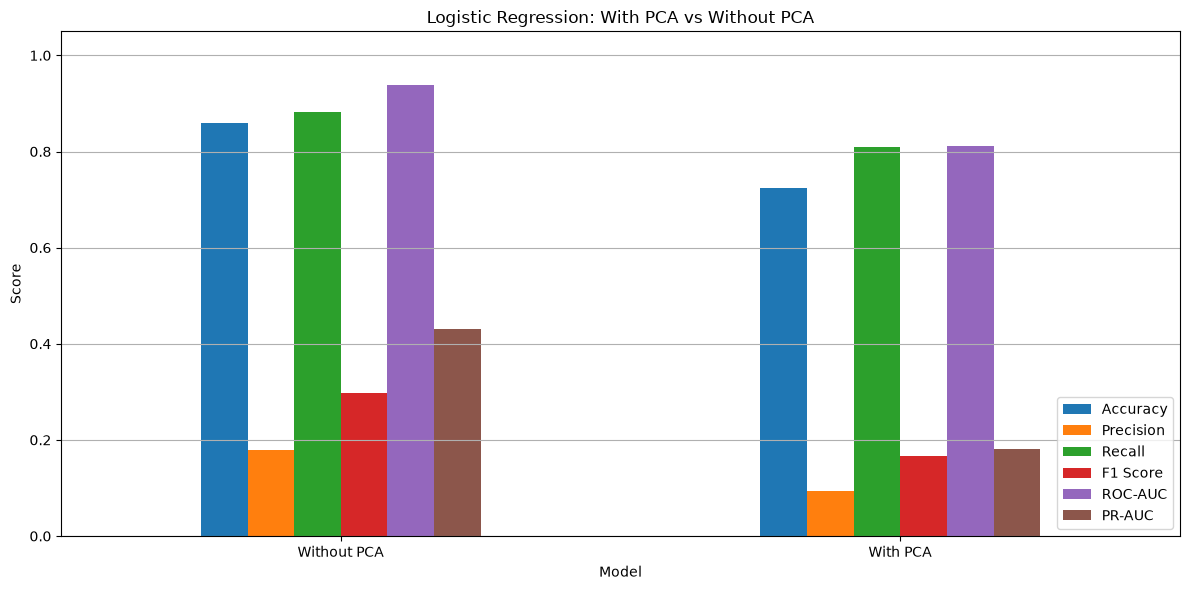

In [12]:
comparison[["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Logistic Regression: With PCA vs Without PCA")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

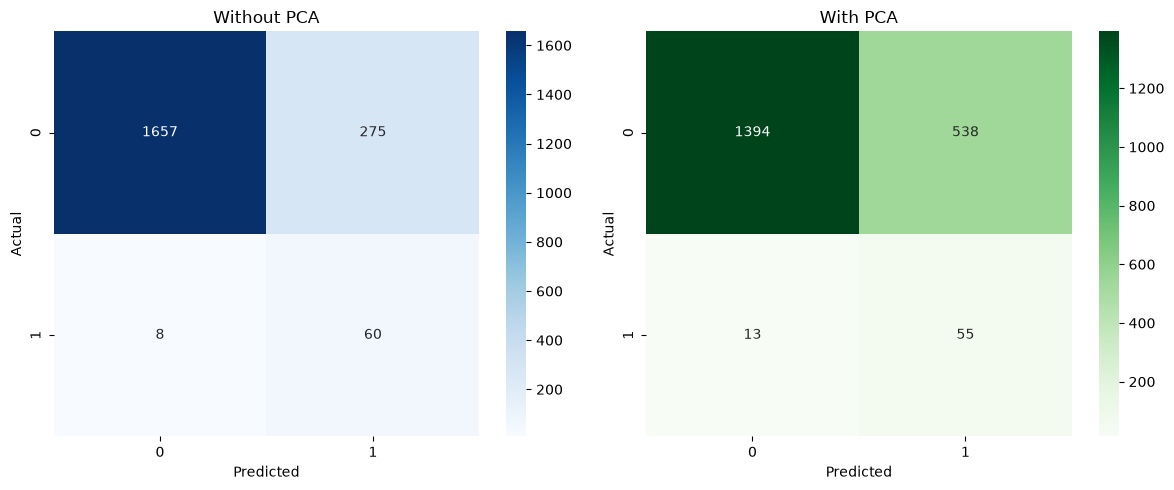

In [13]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_test, pred_original),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Without PCA")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(y_test, pred_pca),
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title("With PCA")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [14]:
os.makedirs("../models", exist_ok=True)
os.makedirs("../results/metrics", exist_ok=True)
os.makedirs("../results/predictions", exist_ok=True)

pca_pipeline = {
    "preprocessor": preprocessor,
    "pca": pca,
    "model": model_pca,
    "features": features,
    "target": target
}

joblib.dump(
    pca_pipeline,
    "../models/pca_pipeline.joblib"
)

comparison.to_csv(
    "../results/metrics/pca_model_comparison.csv"
)

print("PCA pipeline saved successfully.")
print("Model: ../models/pca_pipeline.joblib")
print("Metrics: ../results/metrics/pca_model_comparison.csv")

PCA pipeline saved successfully.
Model: ../models/pca_pipeline.joblib
Metrics: ../results/metrics/pca_model_comparison.csv


In [15]:
pca_predictions = pd.DataFrame({
    "actual_failure": y_test.values,
    "prediction_without_pca": pred_original,
    "probability_without_pca": prob_original,
    "prediction_with_pca": pred_pca,
    "probability_with_pca": prob_pca
})

pca_predictions.to_csv(
    "../results/predictions/pca_test_predictions.csv",
    index=False
)

print("Test predictions saved successfully.")

Test predictions saved successfully.
